# SUN RGB-D class analysis

A separate, detailed analysis of the **entire category vocabulary** of the dataset —
to make an informed decision about which classes to use, which to merge, and which
to exclude.

Inputs (generated by `01_data_preparation.ipynb`; the dataset itself is not needed):

* `outputs/sunrgbd_instances_all.json` — all instances **without** any class filter;
* `outputs/splits/split_assignment.csv` — the std10 train/val/test scene split
  (dataset v2: leak-free groups, stratified);
* `outputs/class_analysis/name_recovery_v2.csv` — the reviewed name-recovery
  decisions of dataset v2 (checked in section 3).

Contents:

1. The long tail of the class vocabulary
2. Most frequent classes: counts and mask sizes
3. Regression check of the name normalization (incl. v2 recovered names)
4. Candidate groups for merging / adding
5. Split coverage and "uncovered" scenes
6. Exclusion candidates
7. Final class map and conclusions

In [1]:
import json, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

OUT_DIR      = Path("outputs")
ANALYSIS_DIR = OUT_DIR / "class_analysis"   # analysis tables are saved here
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Colors (fixed roles throughout the notebook):
C_STD    = "#2a78d6"   # blue   — the standard 10 classes
C_ADD    = "#1baf7a"   # green  — candidates for adding
C_DROP   = "#eb6834"   # orange — exclusion candidates / warnings
C_OTHER  = "#b6b4ad"   # gray   — context, "other"
C_ACCENT = "#eda100"   # yellow — extra accent (test)
SEQ_BLUE = ["#a8c8ee", "#5d9be1", "#1e5da8"]  # one hue, light -> dark
C_TEXT, C_TEXT2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "text.color": C_TEXT, "axes.labelcolor": C_TEXT2,
    "xtick.color": C_TEXT2, "ytick.color": C_TEXT2,
})

# COCO mask-area thresholds (pixels): small < 32^2, large > 96^2
AREA_SMALL, AREA_LARGE = 32 ** 2, 96 ** 2

In [2]:
coco = json.loads((OUT_DIR / "sunrgbd_instances_all.json").read_text())
cat_name  = {c["id"]: c["name"] for c in coco["categories"]}
img_by_id = {im["id"]: im for im in coco["images"]}
print(f"Dataset version: {coco['info'].get('version', 'v1')}")

# scene -> subset of the std10 split (scenes without std10 objects get none)
split_df = pd.read_csv(OUT_DIR / "splits" / "split_assignment.csv")
split_of_scene = dict(zip(split_df.rel_key, split_df.subset))

NO_SPLIT = "no split"
ann_df = pd.DataFrame({
    "name":     [cat_name[a["category_id"]] for a in coco["annotations"]],
    "image_id": [a["image_id"] for a in coco["annotations"]],
    "area":     [a["area"] for a in coco["annotations"]],
})
ann_df["collection"] = ann_df.image_id.map(lambda i: img_by_id[i]["collection"])
ann_df["split"] = ann_df.image_id.map(
    lambda i: split_of_scene.get(img_by_id[i]["rel_key"], NO_SPLIT))

print(f"Scenes: {len(coco['images'])}, instances: {len(ann_df)}, "
      f"unique classes: {ann_df.name.nunique()}")
print(f"Scenes without a std10 split: "
      f"{sum(im['rel_key'] not in split_of_scene for im in coco['images'])}")

Dataset version: v2
Scenes: 10294, instances: 125239, unique classes: 8662
Scenes without a std10 split: 1740


---
## 1. The long tail of the class vocabulary

SUN RGB-D names were typed in by annotators by hand, so the vocabulary is inflated
by typos and one-off names (`2ndchairback`, `1rowofdesksandchairs`). Let's measure
how long-tailed it is and how many classes actually carry data.

,classes,"share of instances, %"
threshold (inst. ≥),,
1,8662,100.0
2,3155,95.6
5,1295,91.8
10,740,88.9
50,216,80.2
100,118,74.7
500,34,59.5


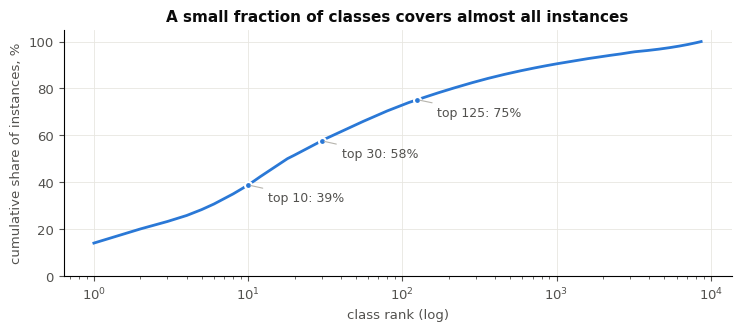

In [3]:
counts = ann_df.name.value_counts()

rows = []
for thr in [1, 2, 5, 10, 50, 100, 500]:
    kept = counts[counts >= thr]
    rows.append({"threshold (inst. ≥)": thr, "classes": len(kept),
                 "share of instances, %": round(kept.sum() / counts.sum() * 100, 1)})
display(pd.DataFrame(rows).set_index("threshold (inst. ≥)"))

cum = counts.cumsum() / counts.sum() * 100
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(range(1, len(cum) + 1), cum.values, color=C_STD, lw=2)
ax.set_xscale("log")
for k in (10, 30, 125):
    ax.annotate(f"top {k}: {cum.iloc[k-1]:.0f}%", xy=(k, cum.iloc[k - 1]),
                xytext=(k * 1.35, cum.iloc[k - 1] - 7), color=C_TEXT2, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=C_OTHER, lw=0.8))
    ax.plot([k], [cum.iloc[k - 1]], "o", color=C_STD, ms=5,
            mec="white", mew=1.5)
ax.set_xlabel("class rank (log)")
ax.set_ylabel("cumulative share of instances, %")
ax.set_title("A small fraction of classes covers almost all instances")
ax.set_ylim(0, 105)
plt.tight_layout(); plt.show()

**Section takeaway.** The ~8.7k-name vocabulary (9.3k before the v2
normalization) is an illusion: three quarters of the names occur only 1–2 times. Everything that matters sits in the top hundred
classes, so the rest of the analysis focuses on it.

---
## 2. Most frequent classes: counts and mask sizes

For every class we compute the number of instances and scenes, plus the
**size profile** using COCO thresholds (small < 32², medium, large > 96² pixels).
The small share is critical: the model segments tiny masks poorly, and a class
dominated by small objects drags the mean mask AP down.

In [4]:
stats = (ann_df.groupby("name")
         .agg(instances=("name", "size"),
              images=("image_id", "nunique"),
              median_area=("area", "median"),
              pct_small=("area", lambda a: (a < AREA_SMALL).mean() * 100),
              pct_large=("area", lambda a: (a > AREA_LARGE).mean() * 100))
         .sort_values("instances", ascending=False))
stats["median_area"] = stats["median_area"].round(0)
stats[["pct_small", "pct_large"]] = stats[["pct_small", "pct_large"]].round(1)

stats.head(100).to_csv(ANALYSIS_DIR / "top_classes.csv")
display(stats.head(40))

,instances,images,median_area,pct_small,pct_large
name,,,,,
chair,17643,5830,6749.0,13.1,42.8
table,7534,4792,13686.0,7.8,58.7
window,4004,2674,10380.0,7.3,53.4
book,3209,1320,1470.0,38.5,8.1
picture,3139,1457,1950.0,32.0,13.8
door,2960,2355,10852.0,5.9,54.4
pillow,2876,1250,3360.0,14.8,16.7
desk,2541,1458,13979.0,8.3,58.7
cabinet,2483,1439,11424.0,5.6,55.7


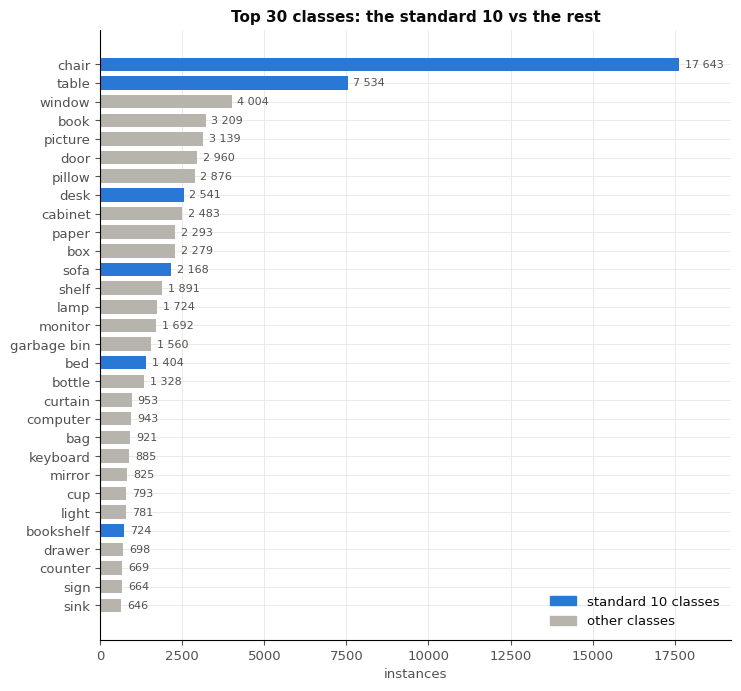

In [5]:
top30 = stats.head(30).iloc[::-1]
colors = [C_STD if n in sd.STANDARD_10_CLASSES else C_OTHER for n in top30.index]

fig, ax = plt.subplots(figsize=(7.5, 7))
bars = ax.barh(top30.index, top30.instances, color=colors, height=0.72)
for b, v in zip(bars, top30.instances):
    ax.text(v + top30.instances.max() * 0.01, b.get_y() + b.get_height() / 2,
            f"{v:,}".replace(",", " "), va="center", fontsize=8, color=C_TEXT2)
ax.set_xlabel("instances")
ax.set_title("Top 30 classes: the standard 10 vs the rest")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_STD, label="standard 10 classes"),
                   plt.Rectangle((0, 0), 1, 1, color=C_OTHER, label="other classes")],
          loc="lower right", frameon=False)
ax.margins(x=0.09)
plt.tight_layout(); plt.show()

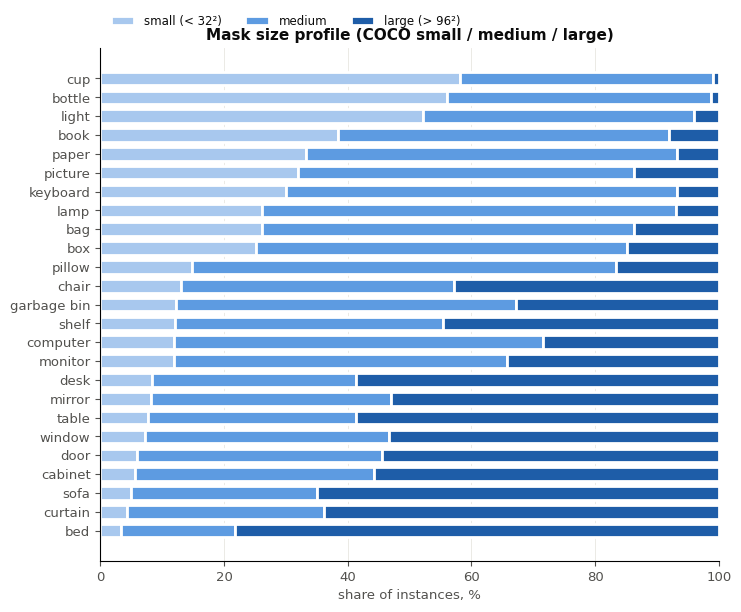

Bottom of the chart — classes with mostly large masks (easier for the model),
top — classes dominated by small masks (low expected AP).


In [6]:
top25 = stats.head(25).copy()
top25["pct_medium"] = 100 - top25.pct_small - top25.pct_large
top25 = top25.sort_values("pct_small")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
left = np.zeros(len(top25))
for frac, col, lab in [(top25.pct_small, SEQ_BLUE[0], "small (< 32²)"),
                       (top25.pct_medium, SEQ_BLUE[1], "medium"),
                       (top25.pct_large, SEQ_BLUE[2], "large (> 96²)")]:
    ax.barh(top25.index, frac, left=left, color=col, height=0.72,
            edgecolor="white", linewidth=2, label=lab)
    left += frac.values
ax.set_xlim(0, 100)
ax.set_xlabel("share of instances, %")
ax.set_title("Mask size profile (COCO small / medium / large)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3, frameon=False,
          fontsize=8.5)
plt.tight_layout(); plt.show()

print("Bottom of the chart — classes with mostly large masks (easier for the model),")
print("top — classes dominated by small masks (low expected AP).")

---
## 3. Regression check: what normalization still misses

`sunrgbd.normalize_name()` folds variants with spaces (`coffee table` → `table`),
concatenated spellings and plurals (`coffeetable`, `officechairs`), and — since
dataset v2 — compound names and typos of the std10 / min400 classes that were
reviewed one by one (`roundtable`, `loveseat`, `computerchair`, `tabel`,
`recyclebin`, ...) plus purely descriptive modifiers (`whiteleathersofa`,
`2ndchair`, `smallcoffeetable`). The reviewed decisions, including every
deliberately **not** mapped name and its reason, are in
`outputs/class_analysis/name_recovery_v2.csv`.

This section is a **regression check** on the generated COCO file:

1. *orthographic losses* — no category name may still squash (spaces, hyphens,
   plural "s") onto an accepted alias;
2. *reviewed recoveries* — no category of the COCO file may still carry a name
   the review mapped to a class (all such instances must have been folded),
   and every mapped name must normalize to its class.

In [7]:
def squash(s):
    return s.replace(" ", "").replace("-", "")

# all accepted aliases of each canonical name: the canon itself + SYNONYMS keys
aliases = defaultdict(set)
for k, v in sd.SYNONYMS.items():
    aliases[v].add(k.strip())
for canon in set(sd.SYNONYMS.values()) | set(sd.STANDARD_10_CLASSES):
    aliases[canon].add(canon)
sq2canon = {squash(a): c for c, al in aliases.items() for a in al}

def match_canon(name):
    sq = squash(name)
    canon = sq2canon.get(sq)
    if canon is None and sq.endswith("s"):        # plurals: chairs, sofas, ...
        canon = sq2canon.get(sq[:-1])
    return canon

lost = []
for name, n in counts.items():
    canon = match_canon(name)
    if canon and canon != name:
        lost.append({"canon": canon, "variant": name, "instances": n})
lost_df = pd.DataFrame(lost, columns=["canon", "variant", "instances"])
lost_df.sort_values("instances", ascending=False).to_csv(
    ANALYSIS_DIR / "orthographic_losses.csv", index=False)
print(f"1. Orthographic losses: {len(lost_df)} names, "
      f"{lost_df.instances.sum()} instances")

# 2. reviewed recoveries (std10 + min400 classes)
from utils.prepare_dataset import SEMANTIC_MERGES
review = pd.read_csv(ANALYSIS_DIR / "name_recovery_v2.csv", keep_default_na=False)
mapped = review[review.mapped_to != "not mapped"]
wrong = [n for n, cls in zip(mapped.name, mapped.mapped_to)
         if SEMANTIC_MERGES.get(sd.normalize_name(n), sd.normalize_name(n)) != cls]
orphans = mapped[mapped.name.isin(counts.index)]
print(f"2. Reviewed names mapped to a class: {len(mapped)} "
      f"({mapped['count'].sum()} instances); not normalizing to their class: "
      f"{len(wrong)}; still present as orphan categories: {len(orphans)} "
      f"({counts.reindex(orphans.name).sum():.0f} instances)")
assert lost_df.empty and not wrong and orphans.empty, "normalization regression"
print("Regression check passed.")

1. Orthographic losses: 0 names, 0 instances
2. Reviewed names mapped to a class: 626 (2570 instances); not normalizing to their class: 0; still present as orphan categories: 0 (0 instances)
Regression check passed.


### Recovered names per class (dataset v2)

Instances of the std10 / min400 classes that v1 lost under compound names or
typos (`new_in_v2`; names that the min400 config already merged through
`SEMANTIC_MERGES`, e.g. `filecabinet`, `dustbin`, `washbasin`, are not counted
again), and the most frequent names that were deliberately left unmapped.

In [8]:
rec = (mapped[mapped.new_in_v2.astype(str) == "True"]
       .groupby("mapped_to")
       .agg(recovered=("count", "sum"), names=("name", "size"),
            top_names=("name", lambda s: ", ".join(s.head(5)))))
merged_counts = ann_df.name.map(lambda n: SEMANTIC_MERGES.get(n, n)).value_counts()
rec["v2 total"] = merged_counts.reindex(rec.index).fillna(0).astype(int)
std_rec = rec.reindex(sd.STANDARD_10_CLASSES).fillna(0)
print(f"std10: +{int(std_rec.recovered.sum())} instances; "
      f"min400 extra classes: +{int(rec.drop(sd.STANDARD_10_CLASSES, errors='ignore').recovered.sum())}")
display(rec.sort_values("recovered", ascending=False))

not_mapped = review[review.mapped_to == "not mapped"]
print("Most frequent names left unmapped (decision and reason):")
display(not_mapped.head(25)[["name", "count", "reason"]])
print(not_mapped.groupby("reason")["count"].sum().sort_values(ascending=False).head(8).to_string())

std10: +987 instances; min400 extra classes: +1107


,recovered,names,top_names,v2 total
mapped_to,,,,
chair,370,113,"rollingchair, computerchair, woodenchair, cush...",17643
garbage bin,307,48,"recyclebin, wastebin, recyclingbin, wastbin, r...",1560
table,285,72,"roundtable, tabel, smalltable, woodentable, co...",7534
cabinet,179,61,"woodencupboard, cupboards, storagecabinet, met...",3250
sofa,162,58,"loveseat, futon, singlesofachair, leathercouch...",2168
display,116,35,"computerscreen, computermoniter, flatscreentv,...",2157
computer,103,15,"computertower, pctower, desktopcomputer, compu...",943
pillow,102,33,"throwpillow, decorativepillow, throwpillows, s...",2876
shelf,88,24,"shelvingunit, woodshelf, woodenshelf, wallshel...",1891


Most frequent names left unmapped (decision and reason):


,name,count,reason
626,light,779,"ceiling / wall lights and fixtures, not the la..."
627,rack,243,"racks of all kinds (coat, dish, spice): not shelf"
628,lightswitch,160,"object part, accessory or attribute"
629,tabletop,107,"object part, accessory or attribute"
630,cabinetdoor,98,"object part, accessory or attribute"
631,flowers,97,"cut flowers / bouquets, not the plant class"
632,desktop,95,"object part, accessory or attribute"
633,bedframe,93,"object part, accessory or attribute"
634,tree,93,"trees, often outdoor / through windows"
635,toiletpaper,88,"object part, accessory or attribute"


reason
object part, accessory or attribute                           2114
different object (the class word is a modifier) or unclear    1519
ceiling / wall lights and fixtures, not the lamp class         779
group or combination of objects                                261
racks of all kinds (coat, dish, spice): not shelf              243
ambiguous (pot / potted plant)                                 100
cut flowers / bouquets, not the plant class                     97
trees, often outdoor / through windows                          93


---
## 4. Candidate groups for merging / adding

Potential merges fall into two kinds:

* **safe** — spelling variants of the same concept
  (`trashcan` = `garbage bin` = `recycle bin`; `cupboard` ≈ `cabinet`);
* **risky** — different concepts that are sometimes merged
  (`stool` → `chair`, `ottoman` → `sofa`, `mattress` → `bed`). Such merges add
  label noise, break comparability with the standard 10-class benchmark, and can
  produce duplicate masks in the same scene (a mattress on top of a bed).

For every candidate group we compute totals **per subset of the std10 split** — the main
viability criterion: is there enough training data, and is there anything to
evaluate on in val/test.

In [9]:
CANDIDATE_GROUPS = {
    "cabinet (+cupboard, file cabinet)": ["cabinet", "cupboard", "filecabinet",
                                          "filingcabinet", "cabnet", "kitchencabinet"],
    "pillow (+cushion)":       ["pillow", "throwpillow"],
    "lamp":                    ["lamp", "tablelamp", "desklamp", "floorlamp"],
    "display (monitor+tv)":    ["monitor", "computermonitor", "tvmonitor",
                                "television", "tvscreen"],
    "garbage bin (full group)": ["garbagebin", "trashcan", "dustbin", "garbagecan",
                                "recyclebin", "wastebin", "trashbin", "wastebasket"],
    "shelf":                   ["shelf", "shelving", "wallshelf"],
    "sink":                    ["sink", "washbasin", "bathroomsink", "kitchensink"],
    "fridge":                  ["fridge", "refrigerator", "refridgerator", "minifridge"],
    "whiteboard (+blackboard)":["whiteboard", "blackboard", "chalkboard"],
    "curtain":                 ["curtain"],
    "mirror":                  ["mirror"],
}

def group_members(squashed_list):
    sqs = set(squashed_list)
    return [n for n in counts.index
            if squash(n) in sqs or (squash(n).endswith("s") and squash(n)[:-1] in sqs)]

rows = []
for gname, sqs in CANDIDATE_GROUPS.items():
    members = group_members(sqs)
    sub = ann_df[ann_df.name.isin(members)]
    by_split = sub.groupby("split").size()
    val_imgs  = sub[sub.split == "val"].image_id.nunique()
    test_imgs = sub[sub.split == "test"].image_id.nunique()
    rows.append({"group": gname, "total": len(sub),
                 "train": by_split.get("train", 0), "val": by_split.get("val", 0),
                 "test": by_split.get("test", 0),
                 NO_SPLIT: by_split.get(NO_SPLIT, 0),
                 "val scenes": val_imgs, "test scenes": test_imgs})
cand_df = (pd.DataFrame(rows).set_index("group")
           .sort_values("total", ascending=False))
cand_df.to_csv(ANALYSIS_DIR / "candidate_groups_splits.csv")
display(cand_df)

# risky merges — volumes only, no recommendation to merge
RISKY = {"stool → chair": ["stool", "barstool"], "ottoman → sofa": ["ottoman"],
         "mattress, bed frame → bed": ["mattress", "bedframe"],
         "urinal → toilet": ["urinal"]}
risky_rows = [{"merge": k, "instances": int(counts[counts.index.isin(group_members(v))].sum())}
              for k, v in RISKY.items()]
print("Risky semantic merges (NOT recommended, for reference only):")
display(pd.DataFrame(risky_rows).set_index("merge"))

,total,train,val,test,no split,val scenes,test scenes
group,,,,,,,
"cabinet (+cupboard, file cabinet)",3250,1500,321,321,1108,181,193
pillow (+cushion),2876,1953,419,419,85,160,174
display (monitor+tv),2127,1390,295,298,144,141,146
shelf,1923,1051,228,223,421,149,129
lamp,1724,1143,245,245,91,146,188
garbage bin (full group),1560,818,175,175,392,115,133
curtain,1031,751,95,89,96,85,69
mirror,825,445,86,98,196,74,87
whiteboard (+blackboard),771,483,114,112,62,88,96


Risky semantic merges (NOT recommended, for reference only):


,instances
merge,
stool → chair,406
ottoman → sofa,169
"mattress, bed frame → bed",246
urinal → toilet,59


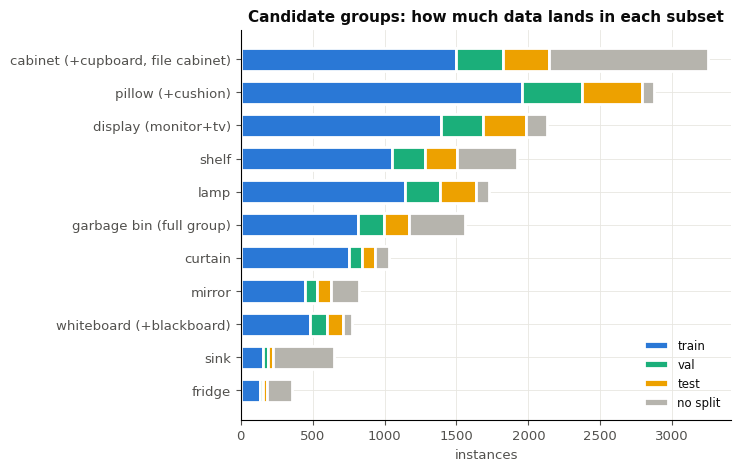

In [10]:
plot_df = cand_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
left = np.zeros(len(plot_df))
for col, colr in [("train", C_STD), ("val", C_ADD), ("test", C_ACCENT),
                  (NO_SPLIT, C_OTHER)]:
    ax.barh(plot_df.index, plot_df[col], left=left, color=colr, height=0.7,
            edgecolor="white", linewidth=2, label=col)
    left += plot_df[col].values
ax.set_xlabel("instances")
ax.set_title("Candidate groups: how much data lands in each subset")
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

---
## 5. Split coverage and "uncovered" scenes

The std10 split in `splits/split_assignment.csv` covers only scenes containing at
least one of the 10 standard classes. Scenes without any such object (mostly
kitchens and bathrooms) get their subset in the extended configs: `splits_min400`
and `splits_min100` inherit the std10 assignment and place the remaining
leak-free groups with the same stratified procedure. The numbers below show how
much of each candidate group std10 alone leaves uncovered.

Scenes without a std10 split: 1740 of 10294 (16.9%)


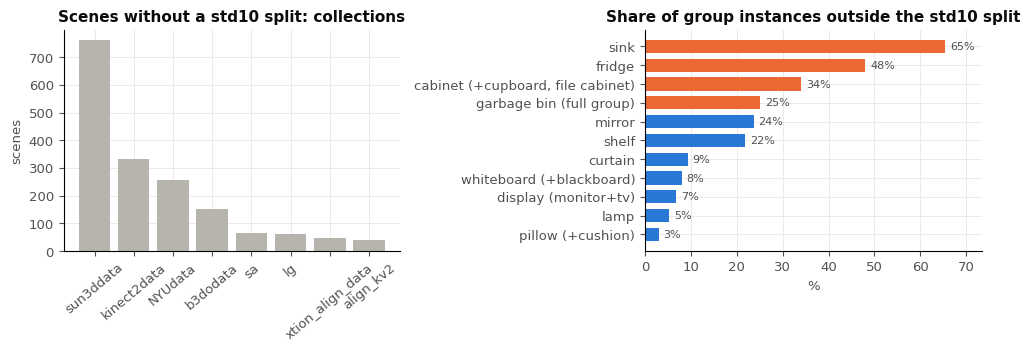

Orange groups (> 25% of data outside the std10 split) rely on the scenes that
only the extended configs assign (splits_min400 / splits_min100).


In [11]:
img_split = {i: split_of_scene.get(im["rel_key"], NO_SPLIT)
             for i, im in img_by_id.items()}
no_split_imgs = [img_by_id[i] for i, s in img_split.items() if s == NO_SPLIT]
print(f"Scenes without a std10 split: {len(no_split_imgs)} of {len(img_by_id)} "
      f"({len(no_split_imgs) / len(img_by_id) * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

coll = pd.Series([im["collection"] for im in no_split_imgs]).value_counts().head(8)
axes[0].bar(coll.index, coll.values, color=C_OTHER)
axes[0].set_title("Scenes without a std10 split: collections")
axes[0].set_ylabel("scenes")
axes[0].tick_params(axis="x", rotation=40)

outside = (cand_df[NO_SPLIT] / cand_df["total"] * 100).sort_values()
bar_cols = [C_DROP if v > 25 else C_STD for v in outside.values]
axes[1].barh(outside.index, outside.values, color=bar_cols, height=0.7)
for y, v in enumerate(outside.values):
    axes[1].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8, color=C_TEXT2)
axes[1].set_title("Share of group instances outside the std10 split")
axes[1].set_xlabel("%")
axes[1].margins(x=0.12)
plt.tight_layout(); plt.show()

print("Orange groups (> 25% of data outside the std10 split) rely on the scenes that")
print("only the extended configs assign (splits_min400 / splits_min100).")

---
## 6. Exclusion candidates

Three reasons not to use a class for instance segmentation with a subsequent
transition to 3D:

* **planar / "stuff"-like** — parts of the room or nearly flat objects:
  instance boundaries are ill-defined, and for point clouds and spatial object
  properties (chapter 3) they carry no meaning;
* **tiny** — most masks are < 32² pixels: at ~640 px input the model barely
  segments such objects, and the class only drags the mean mask AP down;
* **amorphous** — fuzzy boundaries and inconsistent annotation (a pile of
  clothes, a stack of paper).

In [12]:
EXCLUDE = {
    "planar / stuff": ["window", "door", "curtain", "blinds", "mirror",
                       "whiteboard", "picture", "poster", "painting", "carpet",
                       "rug", "counter", "baseboard", "pillar", "board", "sign"],
    "tiny":           ["mouse", "outlet", "cup", "bottle", "faucet", "plate",
                       "bowl", "glass", "vase", "tag", "pricetag", "speaker"],
    "amorphous":      ["clothes", "cloth", "towel", "paper", "box", "bag",
                       "book", "blanket", "pipe"],
}
rows = []
for reason, names in EXCLUDE.items():
    for n in names:
        if n in stats.index:
            s = stats.loc[n]
            rows.append({"class": n, "reason": reason,
                         "instances": int(s.instances),
                         "median area": int(s.median_area),
                         "% small": s.pct_small, "% large": s.pct_large})
excl_df = (pd.DataFrame(rows).set_index("class")
           .sort_values(["reason", "instances"], ascending=[True, False]))
excl_df.to_csv(ANALYSIS_DIR / "exclusion_candidates.csv")
display(excl_df)

n_excl = excl_df["instances"].sum()
print(f"Together these classes cover {n_excl} instances "
      f"({n_excl / len(ann_df) * 100:.1f}% of the dataset) — big numbers do not mean")
print("a class is usable: window/door instance boundaries are arbitrary, and 82% of mouse masks are < 32².")

,reason,instances,median area,% small,% large
class,,,,,
book,amorphous,3209,1470,38.5,8.1
paper,amorphous,2293,1637,33.2,6.8
box,amorphous,2279,2389,25.1,14.8
bag,amorphous,921,2621,26.1,13.8
clothes,amorphous,518,3383,16.2,22.4
towel,amorphous,509,4420,12.8,26.1
blanket,amorphous,320,10228,4.7,51.9
cloth,amorphous,276,3573,16.3,23.6
pipe,amorphous,255,1758,32.2,9.4


Together these classes cover 32302 instances (25.8% of the dataset) — big numbers do not mean
a class is usable: window/door instance boundaries are arbitrary, and 82% of mouse masks are < 32².


---
## 7. Final class map

Every class in the top 100 is a point: frequency vs typical mask size. Color =
role in the proposed scheme. A "good" class for this task sits in the upper right:
many instances and large masks.

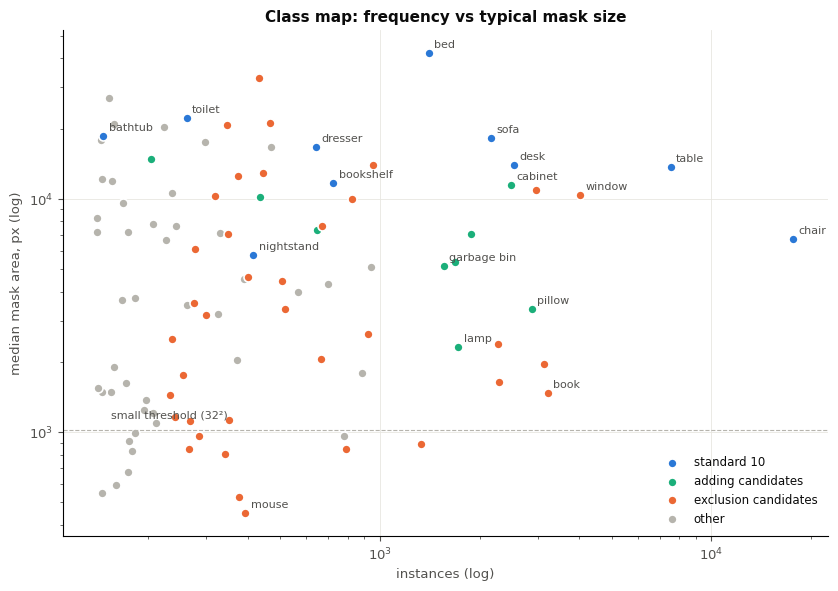

In [13]:
ADD_SET = {"cabinet", "pillow", "lamp", "monitor", "television", "garbage bin",
           "shelf", "sink", "fridge"}
EXCL_SET = {n for names in EXCLUDE.values() for n in names}

top100 = stats.head(100)
roles, role_colors = [], {"standard 10": C_STD, "adding candidates": C_ADD,
                          "exclusion candidates": C_DROP, "other": C_OTHER}
for n in top100.index:
    if n in sd.STANDARD_10_CLASSES: roles.append("standard 10")
    elif n in ADD_SET:              roles.append("adding candidates")
    elif n in EXCL_SET:             roles.append("exclusion candidates")
    else:                           roles.append("other")

fig, ax = plt.subplots(figsize=(8.5, 6))
for role in role_colors:
    idx = [i for i, r in enumerate(roles) if r == role]
    sub = top100.iloc[idx]
    z = 3 if role != "other" else 2
    ax.scatter(sub.instances, sub.median_area, s=42, color=role_colors[role],
               label=role, edgecolors="white", linewidths=1.2, zorder=z)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(AREA_SMALL, color=C_OTHER, lw=0.8, ls="--")
ax.text(top100.instances.min() * 1.1, AREA_SMALL * 1.12, "small threshold (32²)",
        fontsize=8, color=C_TEXT2)
for n in list(sd.STANDARD_10_CLASSES) + ["cabinet", "garbage bin", "window",
                                          "mouse", "book", "pillow", "lamp"]:
    if n in top100.index:
        s = top100.loc[n]
        ax.annotate(n, (s.instances, s.median_area), xytext=(4, 4),
                    textcoords="offset points", fontsize=8, color=C_TEXT2)
ax.set_xlabel("instances (log)")
ax.set_ylabel("median mask area, px (log)")
ax.set_title("Class map: frequency vs typical mask size")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

---
## Conclusions

The numbers below reflect the current artifacts in `outputs/` (dataset v2, see
the computations above).

**1. The vocabulary is inflated, but the core is stable.** Of ~8.7k names only
118 have ≥ 100 instances; the top 30 classes cover ~58% of all objects. The
standard 10 classes are all in the top 100 by frequency (bathtub, the rarest,
is 93rd), with mostly large masks.

**2. Name normalization (regression-checked in section 3).** Concatenated
spellings and plurals (fixed 2026-08-10) and, in dataset v2, 626 reviewed
compound names / typos / descriptively modified names (`roundtable`,
`loveseat`, `computerchair`, `tabel`, `recyclebin`, `whiteleathersofa`, ...)
are folded into their classes: +987 instances for the standard 10 (chair +370,
table +285, sofa +162, desk +69) and +1,107 for the other min400 classes
(garbage bin +307, cabinet +179, display +116, computer +103). Names whose
meaning is not unambiguously one class stay unmapped with a recorded reason
(`name_recovery_v2.csv`): desk-like "X table" and desk/table combos, dressing
table, sofa set / sofa bed, `drawers`, `tube`, `basin`, `cabin`, `rack`,
`light`, flowers and pots, and all object parts and groups.

**3. Viable adding candidates** (the min400 config): `pillow`, `lamp`,
`display` (monitor+tv), `garbage bin` (1,560 instances as a full group), `shelf`.
Be careful with:

* `cabinet` — large (3,250 instances incl. cupboard and file cabinet) but
  visually confusable with `dresser` from the standard ten;
* `sink`, `fridge` — half to two thirds of their data sits in scenes **outside
  the std10 split** (kitchens / bathrooms without standard classes); the extended configs
  assign these scenes (stratified, leak-free) while keeping every std10
  assignment.

**4. Do not use:** planar/stuff (window, door, curtain, mirror, whiteboard,
picture...), tiny (mouse, outlet, cup, bottle — 56–83% of masks below 32²), and
amorphous (clothes, paper, box, bag) classes. Their large counts are deceptive:
annotation quality and geometry make them harmful for mean AP and useless for
point clouds.

**5. Avoid risky merges:** stool→chair, ottoman→sofa, mattress→bed,
urinal→toilet — different concepts; merging adds label noise, breaks
comparability with the standard benchmark (and a mattress also duplicates masks
on top of the bed).